In [1]:
from visualisation_donnees import charger_routes, charger_trips, charger_parcours

df_routes = charger_routes("data/idfm")
df_routes.head(20)

,route_id,agency_id,route_short_name,route_type,route_color,route_text_color,mode
456,IDFM:C01371,IDFM:Operator_100,1,1,FFBE00,000000,metro
457,IDFM:C01372,IDFM:Operator_100,2,1,0055C8,FFFFFF,metro
458,IDFM:C01373,IDFM:Operator_100,3,1,6E6E00,FFFFFF,metro
462,IDFM:C01384,IDFM:Operator_100,14,1,640082,FFFFFF,metro
463,IDFM:C01386,IDFM:Operator_100,3B,1,82C8E6,000000,metro
464,IDFM:C01387,IDFM:Operator_100,7B,1,82DC73,000000,metro
475,IDFM:C01377,IDFM:Operator_100,7,1,FF82B4,000000,metro
1234,IDFM:C01383,IDFM:Operator_100,13,1,82C8E6,000000,metro
1355,IDFM:C01374,IDFM:Operator_100,4,1,A0006E,FFFFFF,metro
1356,IDFM:C01375,IDFM:Operator_100,5,1,FF5A00,000000,metro


In [2]:
df_trips = charger_trips("data/idfm", df_routes)
df_trips.head()

,route_id,trip_id,shape_id,agency_id,route_short_name,route_type,route_color,route_text_color,mode
0,IDFM:C01381,IDFM:RATP:COU_RATP_11DIGAILLAC_2026_Chat01Robp...,IDFM:shp_1_41,IDFM:Operator_100,11,1,6E491E,FFFFFF,metro
1,IDFM:C01381,IDFM:RATP:COU_RATP_11DIGAILLAC_2026_Robp02Robp...,IDFM:shp_1_41,IDFM:Operator_100,11,1,6E491E,FFFFFF,metro
2,IDFM:C01381,IDFM:RATP:COU_RATP_11DIGAILLAC_2026_PteL01Chat...,IDFM:shp_1_119,IDFM:Operator_100,11,1,6E491E,FFFFFF,metro
3,IDFM:C01381,IDFM:RATP:COU_RATP_11DIGAILLAC_2026_Robp02Robp...,IDFM:shp_1_222,IDFM:Operator_100,11,1,6E491E,FFFFFF,metro
4,IDFM:C01381,IDFM:RATP:COU_RATP_11DIGAILLAC_2026_Robp01Robp...,IDFM:shp_1_220,IDFM:Operator_100,11,1,6E491E,FFFFFF,metro


In [3]:
df_parcours = charger_parcours("data/idfm", df_trips)
df_parcours.head()

,shape_id,shape_pt_lat,shape_pt_lon,shape_pt_sequence,route_id,agency_id,route_short_name,route_type,route_color,route_text_color,mode
16670,IDFM:shp_1_100,48.848721,2.298968,0,IDFM:C01376,IDFM:Operator_100,6,1,82DC73,000000,metro
16671,IDFM:shp_1_100,48.847824,2.301867,1,IDFM:C01376,IDFM:Operator_100,6,1,82DC73,000000,metro
16672,IDFM:shp_1_100,48.847511,2.302942,2,IDFM:C01376,IDFM:Operator_100,6,1,82DC73,000000,metro
16673,IDFM:shp_1_100,48.847511,2.302942,3,IDFM:C01376,IDFM:Operator_100,6,1,82DC73,000000,metro
16674,IDFM:shp_1_100,48.846603,2.306028,4,IDFM:C01376,IDFM:Operator_100,6,1,82DC73,000000,metro


In [4]:
import geopandas as gpd
import pandas as pd
from visualisation_donnees import (
    charger_routes, charger_trips, charger_parcours,
    construire_lignes_idfm, charger_arrets, charger_stations,
)

df_routes = charger_routes("data/idfm")
df_trips = charger_trips("data/idfm", df_routes)
df_parcours = charger_parcours("data/idfm", df_trips)
gpd_idfm = construire_lignes_idfm(df_parcours)
df_arrets = charger_arrets("data/idfm", df_trips)
df_stations = charger_stations("data/idfm", df_arrets)

In [5]:
gpd_stations = gpd.GeoDataFrame(
    df_stations,
    geometry=gpd.points_from_xy(df_stations["stop_lon"], df_stations["stop_lat"]),
    crs="EPSG:4326",
).to_crs("EPSG:2154")

In [6]:
gpd_idfm["longueur"] = gpd_idfm.length
trace_ref = gpd_idfm.sort_values("longueur", ascending=False).drop_duplicates("route_id")
trace_ref = pd.DataFrame(trace_ref[["route_id", "geometry"]]).rename(columns={"geometry": "trace"})

In [7]:
stations = gpd_stations.merge(trace_ref, on="route_id")

# distance entre la station et le tracé (pour repérer les stations d'une autre branche)
stations["distance_trace"] = stations.apply(lambda r: r["trace"].distance(r["geometry"]), axis=1)
# position le long du tracé, en km
stations["position_km"] = stations.apply(lambda r: r["trace"].project(r["geometry"]) / 1000, axis=1)

stations = stations[stations["distance_trace"] < 300]
stations = stations.sort_values(["route_short_name", "position_km"])

In [8]:
# faire commencer chaque ligne à 0 km
stations["position_km"] = stations["position_km"] - stations.groupby("route_short_name")["position_km"].transform("min")

# arrondir à 1 chiffre après la virgule
stations["position_km"] = stations["position_km"].round(2)

In [9]:
stations.loc[stations["route_short_name"] == "6", ["stop_name", "position_km"]]

,stop_name,position_km
450,Charles de Gaulle - Étoile,0.00
293,Kléber,0.51
416,Boissière,1.02
473,Trocadéro,1.48
511,Passy,2.15
528,Bir-Hakeim,2.67
559,Dupleix,3.06
555,La Motte-Picquet - Grenelle,3.57
548,Cambronne,3.85
586,Sèvres-Lecourbe,4.55


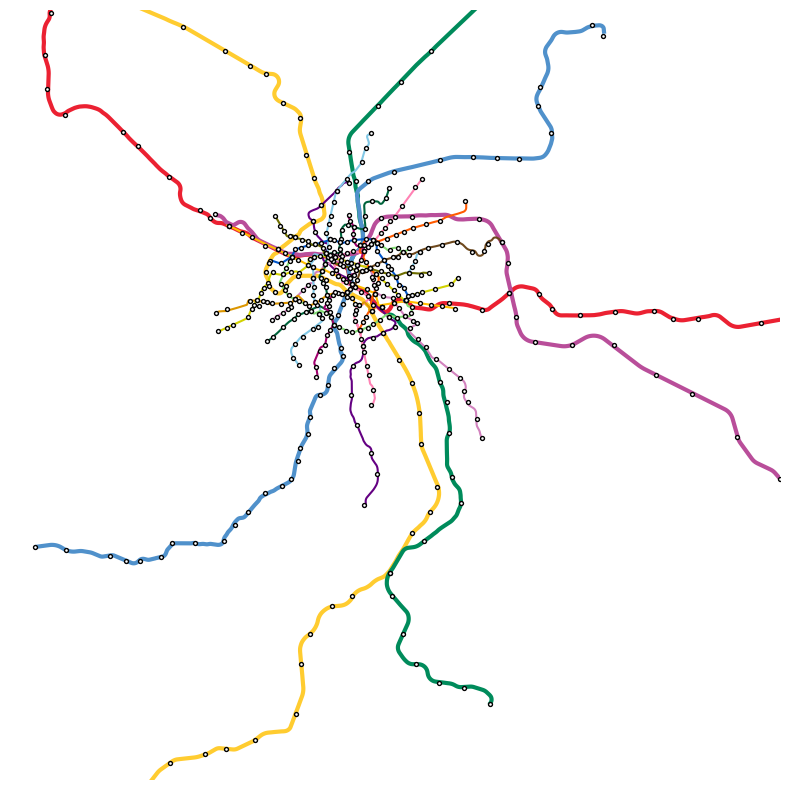

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# le tracé le plus long de chaque ligne (avec ses couleurs)
traces = gpd_idfm.sort_values("longueur", ascending=False).drop_duplicates("route_id")

ax = traces.plot(
    color="#" + traces["route_color"],
    linewidth=np.where(traces["mode"] == "metro", 1.5, 3),  # RER plus épais
    figsize=(10, 10),
)
stations.plot(ax=ax, color="white", edgecolor="black", markersize=8, zorder=5)

ax.set_xlim(630_000, 680_000)  # zoom sur Paris et la petite couronne
ax.set_ylim(6_830_000, 6_880_000)
ax.set_axis_off()
plt.savefig("carte_lignes_idfm.png", dpi=300, bbox_inches="tight")
plt.show()

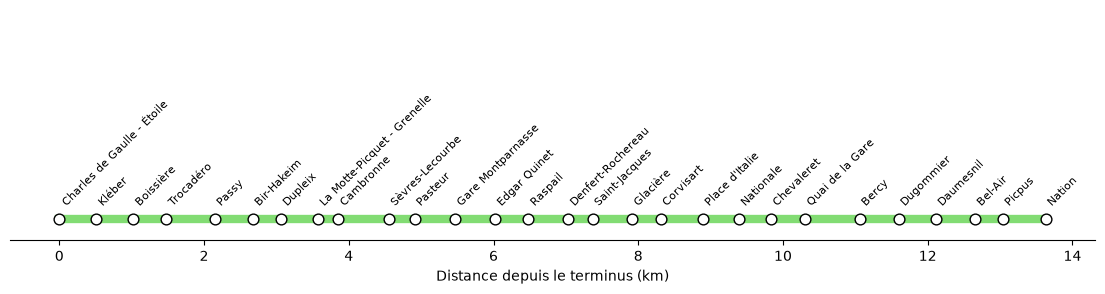

In [11]:
num = "6"
arrets = stations[stations["route_short_name"] == num].sort_values("position_km")
couleur = "#" + arrets["route_color"].iloc[0]

fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(arrets["position_km"], [0] * len(arrets), color=couleur, linewidth=6)
ax.scatter(arrets["position_km"], [0] * len(arrets),
           color="white", edgecolor="black", s=60, zorder=3)

for _, a in arrets.iterrows():
    ax.annotate(
        a["stop_name"],
        xy=(a["position_km"], 0),         
        xytext=(0, 8),                     
        textcoords="offset points",
        rotation=45, fontsize=8,
        ha="left", va="bottom",
    )

ax.set_xlabel("Distance depuis le terminus (km)")
ax.set_yticks([])
ax.spines[["left", "top", "right"]].set_visible(False)
ax.set_ylim(-0.1, 1)
plt.show()

In [ ]:
%pip install cartiflette

In [16]:
%pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 89.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ipywidgets]3 [ipywidgets]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [22]:
#CELLULE A 
df_mob = pd.read_parquet("RP2023_mobpro.parquet")
print(df_mob.columns.tolist())

['COMMUNE', 'ARM', 'DCFLT', 'DCLT', 'AGEREVQ', 'GS', 'DEROU', 'DIPL', 'EMPL', 'ILT', 'ILTUU', 'IMMI', 'INATC', 'INEEM', 'INPOM', 'INPSM', 'IPONDI', 'LPRM', 'METRODOM', 'MOCO', 'NA5', 'NPERR', 'REGION', 'REGLT', 'SEXE', 'STAT', 'STOCD', 'TP', 'TRANS', 'TYPL', 'TYPMR', 'VOIT']


In [ ]:
#CELLULE B
noms_csp = {
    "1": "Agriculteurs",
    "2": "Artisans, commerçants, chefs d'entreprise",
    "3": "Cadres",
    "4": "Professions intermédiaires",
    "5": "Employés",
    "6": "Ouvriers",
}
noms_mode = {
    "1": "Pas de transport",
    "2": "Marche",
    "3": "Vélo",
    "4": "Deux-roues motorisé",
    "5": "Voiture",
    "6": "Transports en commun",
}

df_mob["CSP"] = df_mob["GS"].map(noms_csp)
df_mob["mode"] = df_mob["TRANS"].astype(str).map(noms_mode)

def joli(serie):#jsuis relou mais je veux un joli affichage des données , comme ca c'est + clair
    """Arrondit, enlève le .0 et sépare les milliers par un espace"""
    return serie.round().astype(int).map(lambda x: f"{x:,}".replace(",", " "))

#données pondérées grace a la colonne IPONDI 
print(joli(df_mob.groupby("CSP")["IPONDI"].sum().sort_values(ascending=False)))
print()
print(joli(df_mob.groupby("mode")["IPONDI"].sum().sort_values(ascending=False)))


CSP
Cadres                                       2 000 706
Professions intermédiaires                   1 418 387
Employés                                     1 335 778
Ouvriers                                       683 307
Artisans, commerçants, chefs d'entreprise      317 268
Agriculteurs                                     5 393
Name: IPONDI, dtype: str

mode
Transports en commun    2 519 315
Voiture                 2 203 234
Marche                    414 172
Vélo                      284 624
Pas de transport          199 449
Deux-roues motorisé       140 044
Name: IPONDI, dtype: str


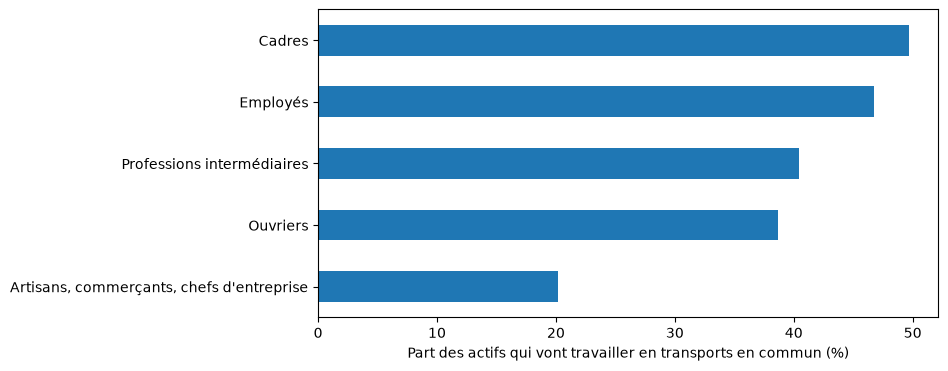

In [34]:
#CELLULE C
df_mob["poids_tc"] = df_mob["IPONDI"] * df_mob["tc"]
somme = df_mob.groupby("CSP")[["poids_tc", "IPONDI"]].sum()
part_tc = somme["poids_tc"] / somme["IPONDI"] * 100

part_tc = part_tc.drop("Agriculteurs")  # trop peu nombreux pour être fiables

ax = part_tc.sort_values().plot(kind="barh", color="#1f77b4", figsize=(8, 4))
ax.set_xlabel("Part des actifs qui vont travailler en transports en commun (%)")
ax.set_ylabel("")
plt.show()

#visualisation num 6 

In [47]:
#CELLULE D : récuper les délimitation des communes 
import numpy as np

url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/regions/ile-de-france/communes-ile-de-france.geojson"
communes = gpd.read_file(url)

communes = communes.rename(columns={"code": "INSEE_COM"})
communes = communes.to_crs("EPSG:2154")[["INSEE_COM", "nom", "geometry"]]
communes.head()

,INSEE_COM,nom,geometry
0,77322,Moussy-le-Neuf,"POLYGON ((671540.099 6888415.654, 672018.657 6..."
1,77323,Moussy-le-Vieux,"POLYGON ((670847.005 6881770.499, 670814.257 6..."
2,91247,Forêt-le-Roi,"POLYGON ((628602.786 6818686.939, 628098.295 6..."
3,94001,Ablon-sur-Seine,"POLYGON ((656675.727 6847486.201, 657009.353 6..."
4,94018,Charenton-le-Pont,"POLYGON ((657381.09 6857583.672, 657109.665 68..."


In [48]:
#CELLULE D bis : trouver l'arrondissement + données georgraphiques de paris
url_arr = "https://opendata.paris.fr/api/explore/v2.1/catalog/datasets/arrondissements/exports/geojson"
arr = gpd.read_file(url_arr)
arr = arr.rename(columns={"c_arinsee": "INSEE_COM", "l_ar": "nom"})
arr["INSEE_COM"] = arr["INSEE_COM"].astype(int).astype(str)
arr = arr.to_crs("EPSG:2154")[["INSEE_COM", "nom", "geometry"]]

communes = pd.concat([communes[communes["INSEE_COM"] != "75056"], arr], ignore_index=True)
communes.tail()

,INSEE_COM,nom,geometry
1290,75119,19ème Ardt,"POLYGON ((655238.908 6866974.758, 655290.661 6..."
1291,75113,13ème Ardt,"POLYGON ((654119.17 6859954.677, 654269.366 68..."
1292,75107,7ème Ardt,"POLYGON ((648698.567 6861464.29, 648584.964 68..."
1293,75101,1er Ardt,"POLYGON ((650706.58 6863530.88, 650848.899 686..."
1294,75103,3ème Ardt,"POLYGON ((653331.96 6863240.808, 653336.416 68..."


In [49]:
#CELLULE E
stations_com = gpd.sjoin(
    stations.drop(columns=["trace"]),
    communes,
    predicate="within",
)
stations_com[["route_short_name", "stop_name", "nom"]].head(10)

,route_short_name,stop_name,nom
155,1,La Défense,Puteaux
343,1,Esplanade de la Défense,Puteaux
376,1,Pont de Neuilly,Neuilly-sur-Seine
40,1,Les Sablons,Neuilly-sur-Seine
402,1,Neuilly - Porte Maillot,17ème Ardt
448,1,Argentine,17ème Ardt
452,1,Charles de Gaulle - Étoile,8ème Ardt
429,1,George V,8ème Ardt
431,1,Franklin D. Roosevelt,8ème Ardt
414,1,Champs-Élysées - Clemenceau,8ème Ardt


In [50]:
#CELLULE F
# code géographique : l'arrondissement si on habite Paris, sinon la commune
df_mob["code_geo"] = np.where(
    df_mob["COMMUNE"] == "75056", df_mob["ARM"].astype(str), df_mob["COMMUNE"]
)

df_mob["poids_ouv"] = df_mob["IPONDI"] * (df_mob["CSP"] == "Ouvriers")
somme = df_mob.groupby("code_geo")[["poids_ouv", "IPONDI"]].sum()
part_ouv = (somme["poids_ouv"] / somme["IPONDI"] * 100).round(1).rename("part_ouvriers")

# on enlève l'ancienne colonne si la cellule a déjà été lancée (évite les doublons)
stations_com = stations_com.drop(columns=["part_ouvriers"], errors="ignore")
stations_com = stations_com.merge(part_ouv, left_on="INSEE_COM", right_index=True, how="left")

stations_com[["stop_name", "nom", "part_ouvriers"]].rename(
    columns={"stop_name": "Station", "nom": "Commune", "part_ouvriers": "Part d'ouvriers (%)"}
).head(10)

,Station,Commune,Part d'ouvriers (%)
155,La Défense,Puteaux,3.9
343,Esplanade de la Défense,Puteaux,3.9
376,Pont de Neuilly,Neuilly-sur-Seine,2.5
40,Les Sablons,Neuilly-sur-Seine,2.5
402,Neuilly - Porte Maillot,17ème Ardt,4.6
448,Argentine,17ème Ardt,4.6
452,Charles de Gaulle - Étoile,8ème Ardt,3.5
429,George V,8ème Ardt,3.5
431,Franklin D. Roosevelt,8ème Ardt,3.5
414,Champs-Élysées - Clemenceau,8ème Ardt,3.5


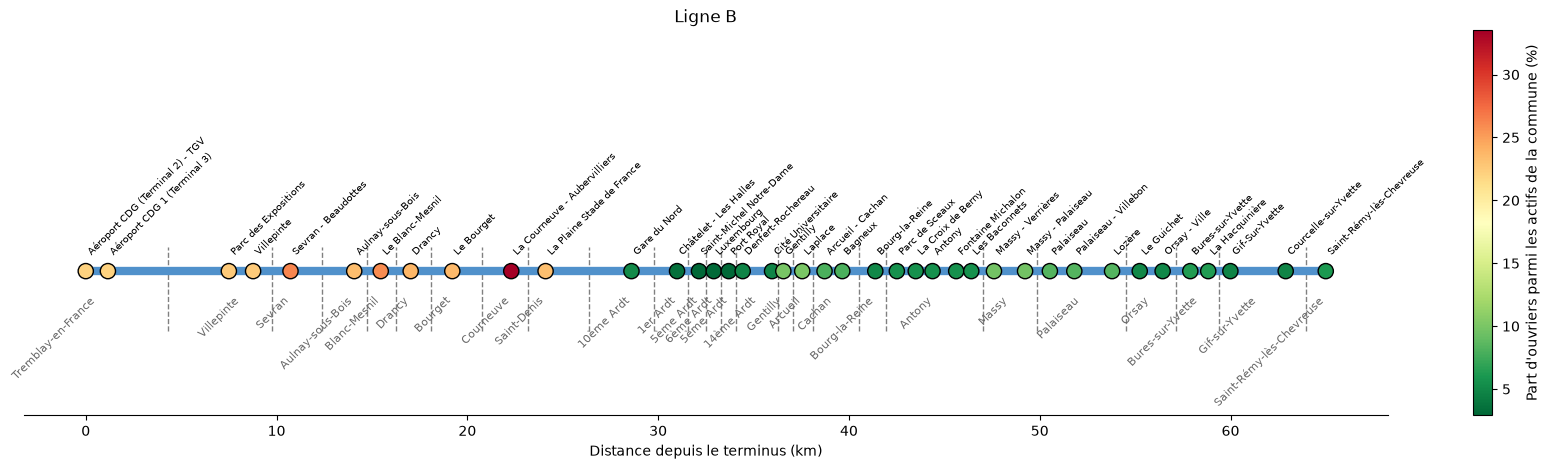

In [53]:
#CELLULE G 
num = "B"  # essaie aussi "14", "A", "B", "D"...
arrets = stations_com[stations_com["route_short_name"] == num].sort_values("position_km").reset_index(drop=True)
couleur = "#" + arrets["route_color"].iloc[0]

fig, ax = plt.subplots(figsize=(22, 5))
ax.plot(arrets["position_km"], [0] * len(arrets), color=couleur, linewidth=6, zorder=1)
points = ax.scatter(
    arrets["position_km"], [0] * len(arrets),
    c=arrets["part_ouvriers"], cmap="RdYlGn_r",  # rouge = beaucoup d'ouvriers
    s=120, edgecolor="black", zorder=2,
)

# noms des stations
for _, a in arrets.iterrows():
    ax.annotate(a["stop_name"], xy=(a["position_km"], 0), xytext=(0, 10),
                textcoords="offset points", rotation=45, fontsize=7,
                ha="left", va="bottom")

# --- délimitation des communes ---
arrets["bloc"] = (arrets["nom"] != arrets["nom"].shift()).cumsum()
blocs = arrets.groupby("bloc").agg(
    nom=("nom", "first"),
    debut=("position_km", "min"),
    fin=("position_km", "max"),
)

# trait pointillé à mi-chemin entre deux communes
for i in range(len(blocs) - 1):
    frontiere = (blocs["fin"].iloc[i] + blocs["debut"].iloc[i + 1]) / 2
    ax.vlines(frontiere, -0.25, 0.1, color="gray", linestyle="--", linewidth=1, zorder=0)

# nom de la commune, incliné sous ses stations
for _, b in blocs.iterrows():
    ax.text((b["debut"] + b["fin"]) / 2, -0.1, b["nom"],
            rotation=45, ha="right", va="top", fontsize=8, color="dimgray")

fig.colorbar(points, ax=ax, label="Part d'ouvriers parmi les actifs de la commune (%)")
ax.set_ylim(-0.6, 1)
ax.set_yticks([])
ax.set_xlabel("Distance depuis le terminus (km)")
ax.spines[["left", "top", "right"]].set_visible(False)
ax.set_title(f"Ligne {num}")
plt.show()